In [1]:
# Kaggle & local auto-reproducibility setup (hidden on Kaggle)
from __future__ import annotations

import os
from pathlib import Path
import subprocess
import sys

EXPECTED_FIGS = [
    "fig1_hero_palmer_vs_dike.png",
    "fig2_scouting_blindspot.png",
    "fig3_combine_to_nfl_bridge.png",
    "fig4_lodco_cv_performance.png",
    "fig5_draft_room_quadrant.png",
]

ON_KAGGLE = Path("/kaggle/working").exists() and Path("/kaggle/input").exists()


def _find_under(root: Path, required_files: tuple[str, ...], max_depth: int = 4) -> Path | None:
    if not root.exists():
        return None
    for cur, dirs, files in os.walk(root):
        cur_p = Path(cur)
        if all(req in files for req in required_files):
            return cur_p
        if len(cur_p.relative_to(root).parts) >= max_depth:
            dirs[:] = []
    return None


def _resolve_out_dir() -> Path:
    if os.environ.get("BDB_OUT_DIR"):
        return Path(os.environ["BDB_OUT_DIR"]).resolve()
    if ON_KAGGLE:
        return Path("/kaggle/working")
    return Path("..").resolve()


def _resolve_raw_dir() -> Path:
    if os.environ.get("BDB_RAW_DIR"):
        return Path(os.environ["BDB_RAW_DIR"]).resolve()
    default_kaggle = Path("/kaggle/input/nfl-big-data-bowl-2027")
    if (default_kaggle / "games.csv").exists():
        return default_kaggle
    if ON_KAGGLE:
        found = _find_under(Path("/kaggle/input"), ("games.csv", "combine_tracking.csv"), max_depth=4)
        if found is not None:
            return found
    return (Path("..") / "data" / "raw").resolve()


def _find_pipeline_script() -> Path:
    local_cand = (Path("..") / "kaggle_dataset_src" / "run_all_pipeline.py").resolve()
    if ON_KAGGLE:
        found = _find_under(Path("/kaggle/input"), ("run_all_pipeline.py", "09_generate_visuals.py"), max_depth=4)
        if found is not None:
            return found / "run_all_pipeline.py"
    if local_cand.exists():
        return local_cand
    raise FileNotFoundError(
        "Could not locate run_all_pipeline.py in /kaggle/input/ or ../kaggle_dataset_src/."
    )


OUT_DIR = _resolve_out_dir()
RAW_DIR = _resolve_raw_dir()
FIG_DIR = OUT_DIR / "figures"
PROC_DIR = OUT_DIR / "data" / "processed"

artifacts_ready = (PROC_DIR / "wr_targets.parquet").exists() and all(
    (FIG_DIR / fname).exists() and (FIG_DIR / fname).stat().st_size > 0 for fname in EXPECTED_FIGS
)

if ON_KAGGLE or os.environ.get("BDB_FORCE_PIPELINE") == "1" or not artifacts_ready:
    pipeline_script = _find_pipeline_script()
    env = os.environ.copy()
    env["BDB_RAW_DIR"] = str(RAW_DIR)
    env["BDB_OUT_DIR"] = str(OUT_DIR)
    env["MPLBACKEND"] = "Agg"
    env["PYTHONUNBUFFERED"] = "1"
    print(f"[setup] Running full pipeline via {pipeline_script} ...")
    subprocess.run([sys.executable, str(pipeline_script)], env=env, check=True)
else:
    print(f"[setup] Using verified local artifacts in {OUT_DIR}")

for fname in EXPECTED_FIGS:
    assert (FIG_DIR / fname).exists(), f"Missing generated figure: {FIG_DIR / fname}"


# From Track Speed to Route Kinetics: Decoding NFL Combine Skill Drills to Predict Receiver Separation

Every February, NFL front offices anchor draft boards to one headline stopwatch metric from Indianapolis: the 40-yard dash. Yet wide receivers never earn open windows on Sundays by running unguarded in a straight track lane. They win by carrying acceleration into route stems, braking sharply before a stem bend, and exploding out of cuts against coverage leverage.

Compare two recent draft prospects with nearly identical Combine frames and timed straight-line speed: **Trey Palmer** (2023, Rd 6 #191, 192 lb, 4.33s 40-yd) and **Chimere Dike** (2025, Rd 4 #103, 196 lb, 4.34s 40-yd). Across identical Combine tracking drills (`GO_ROUTE_RIGHT` and `COMEBACK_ROUTE_RIGHT`), tracking sensors immediately separate how both receivers move. As Figure 1 shows, Palmer reached 10.98 yd/s on the vertical Go route and 8.43 yd/s entering his Comeback break, maintaining higher velocity smoothly through his stem and turn, whereas Dike topped out at 10.13 yd/s on the Go and slowed earlier into his Comeback at 7.93 yd/s.

That Indianapolis kinetic gap translated directly onto NFL Sundays. Across regular-season game tracking frames from snap to pass release (15,344 frames for Palmer versus 10,592 for Dike), Palmer sustained a higher 95th-percentile route speed (8.55 vs. 8.19 yd/s) and generated +0.211 yd of context-adjusted separation over expected on breaking routes (`soe_break`) versus -0.256 yd for Dike — a **0.47-yard separation swing** completely invisible to the stopwatch and draft round.

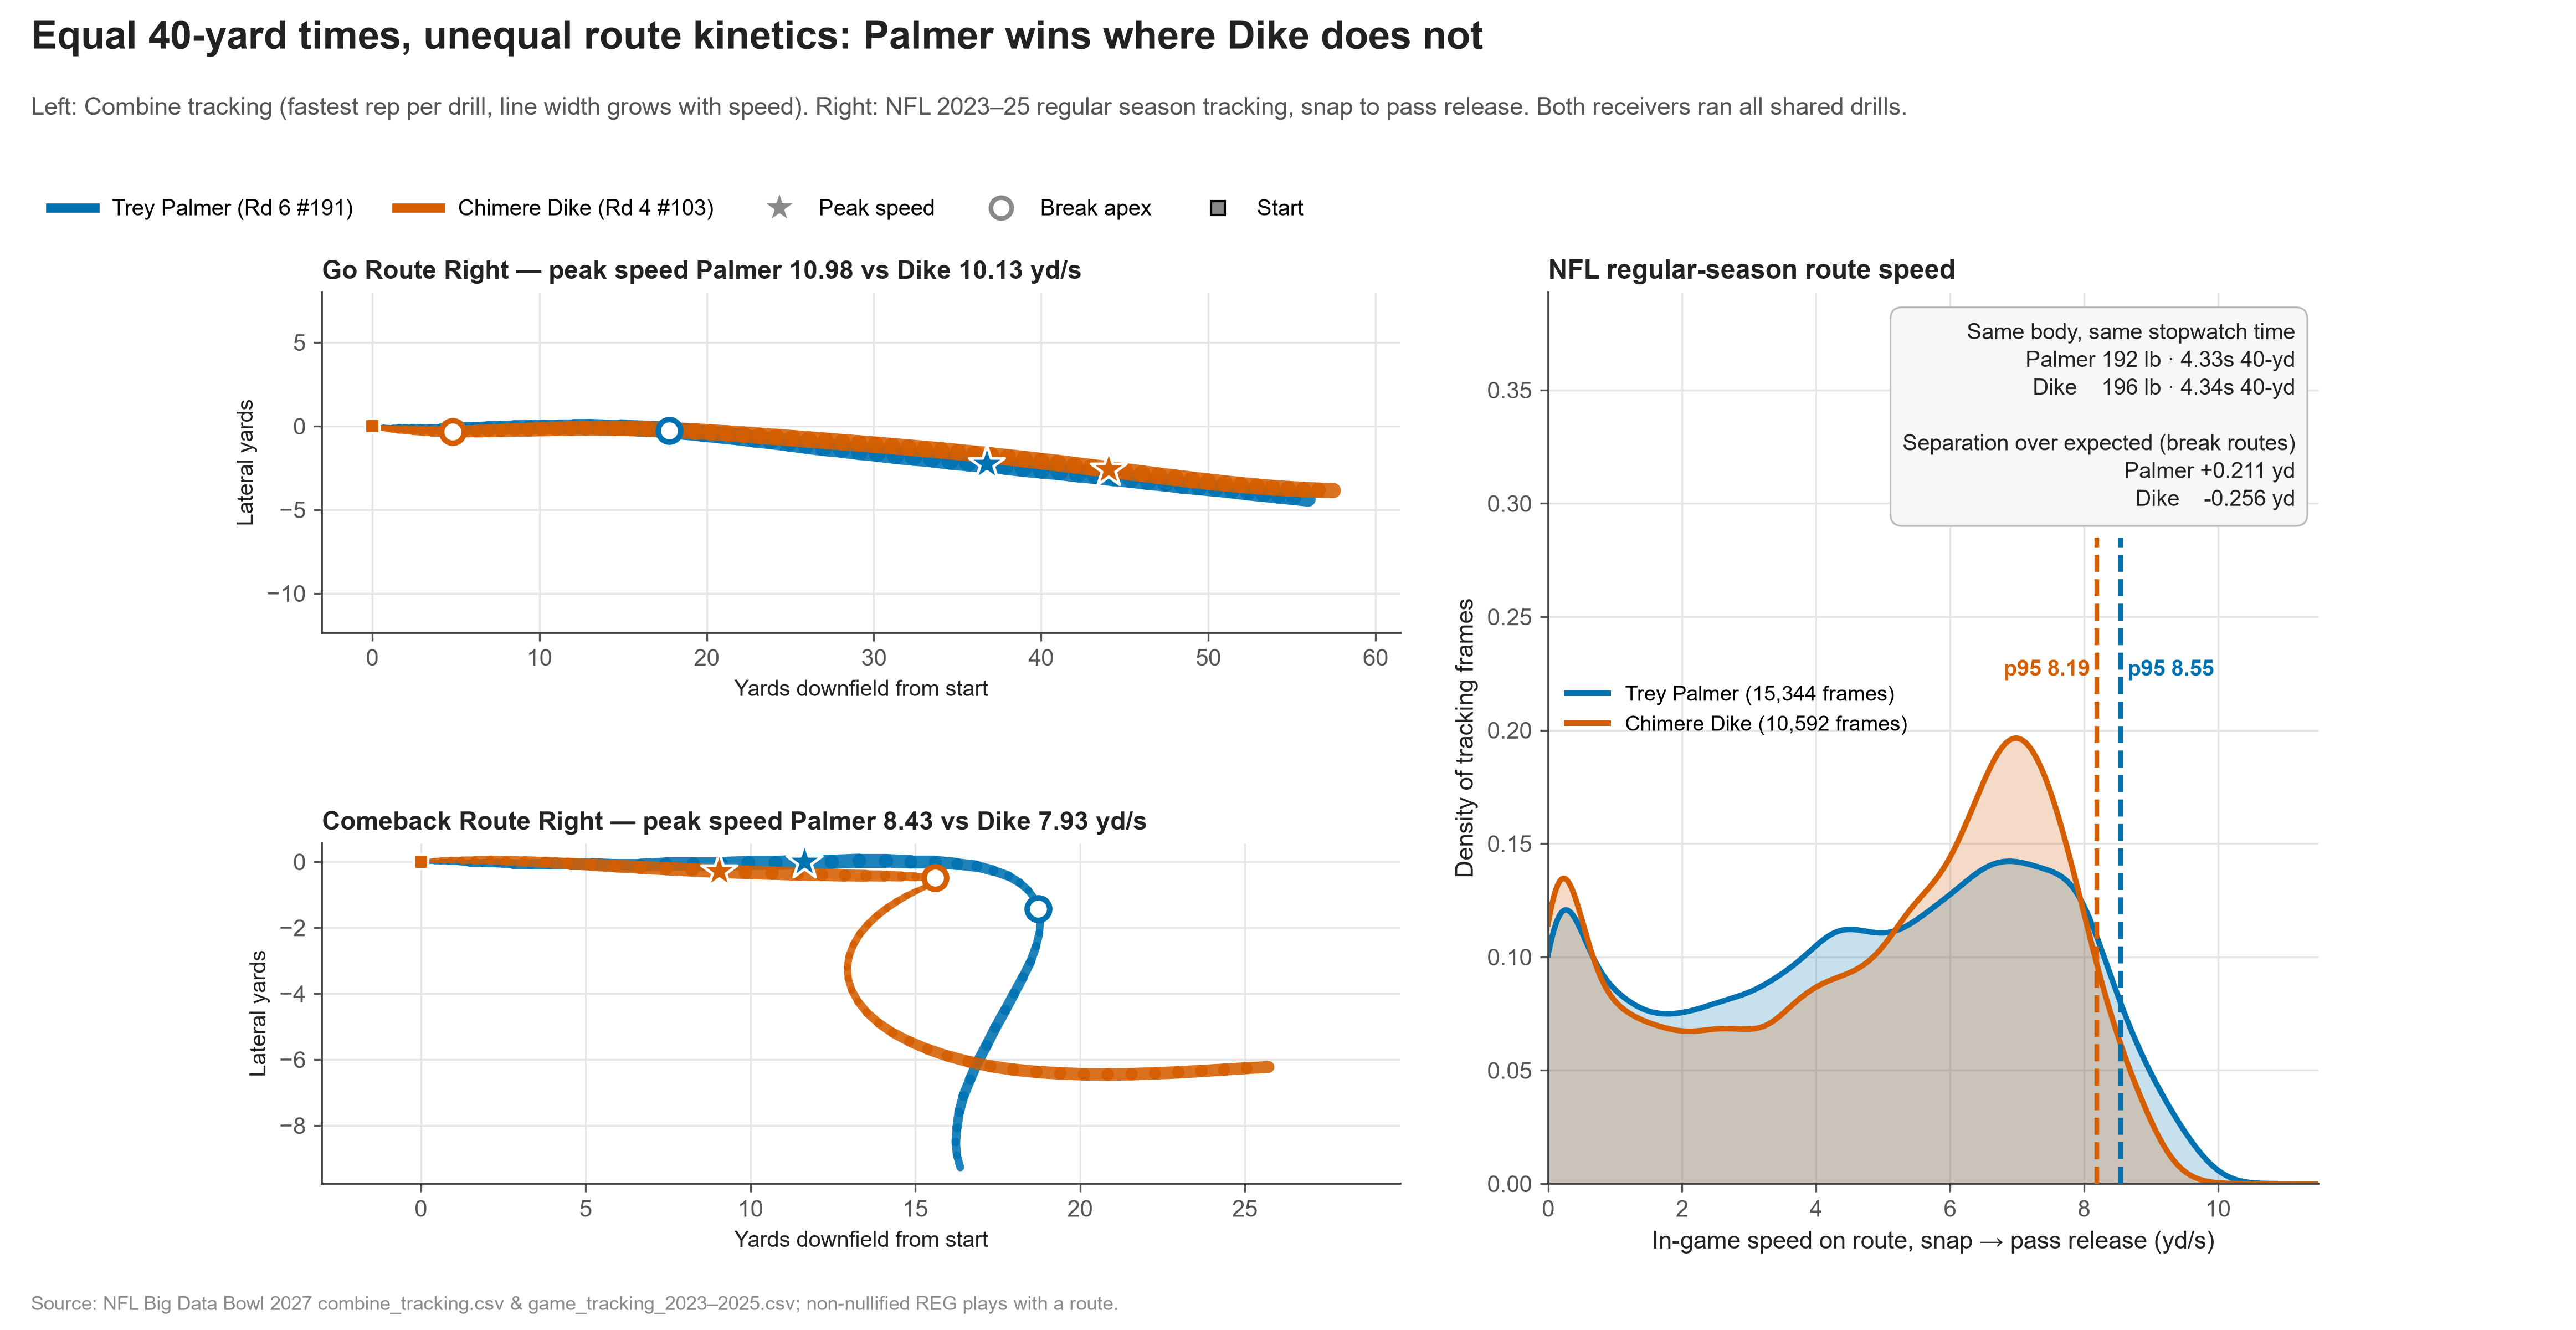

In [2]:
from pathlib import Path
from IPython.display import Image, display

fig_root = Path(globals().get('FIG_DIR', Path('../figures')))
fig_path = fig_root / 'fig1_hero_palmer_vs_dike.png'
assert fig_path.exists(), f'Missing figure: {fig_path}'
display(Image(filename=str(fig_path)))


## Data & Methodology

### Context-Neutral NFL Target: Break-Route Separation Over Expected (`soe_break`)
Across the 2023–2025 Combine cohorts (510 Combine prospects across five positions, including 107 wide receivers tracked across 1,529 skill-drill repetitions), we linked Indianapolis player-tracking files to NFL regular-season route tracking (`season_type` == `REG`, `play_nullified_by_penalty` == `N`, franchise code `LA` normalized to `LAR`). This matched 31,035 valid route plays across 83 receivers (69 with ≥ 50 regular-season route snaps).

Raw separation at throw (3.11 yd league mean, SD = 2.12 yd) heavily rewards soft off-coverage cushions and shallow checkdown designs rather than route-running skill. To isolate individual separation creation, we trained a Leave-One-Season-Out LightGBM regressor predicting `separation_at_pass_forward` solely from seven pre-throw contextual variables: `route_ran` (36.1% gain share), pre-snap `cushion` (24.3%), `team_coverage_type` (16.0%), `team_coverage_man_zone` (12.7%), `pass_length`, `in_motion_at_ball_snap`, and `lined_up_position`. Out-of-fold predictions generalized steadily across all three NFL seasons (2023 $R^2 = 0.325$, 2024 $0.331$, 2025 $0.284$; **overall OOF $R^2 = 0.310$**, RMSE = 1.757 yd, MAE = 1.329 yd). Play-level residuals (actual − expected) were shrunk per receiver toward cohort priors using Empirical Bayes shrinkage ($k_{\text{all}}=50$, $k_{\text{man}}=30$, $k_{\text{break}}=40$), preventing small-sample noise from exaggerating low-volume backups. Our primary evaluation metric is `soe_break`, targeting cut-intensive breaking routes (`OUT`, `IN`, `HITCH`, `SLANT`, `CORNER`; 16,062 target plays across 62 receivers reaching ≥ 50 break snaps).

### Biomechanical Segmentation, Homogeneous Families & Clean Sensor Indices
Combine skill tracking reports 10 Hz center-of-mass coordinates (`x`, `y`) and kinematics (`s`, `a`, `dir`) without upper-body orientation (`o`). Pooling contrasting drills—such as heavy-braking comebacks approaching -7 yd/s² against vertical go routes—or taking unconstrained turning-rate maxima (which mistakenly capture post-drill slowdowns past 80% of trajectory length) severely corrupts physical inference. Across 1,105 reps spanning 10 core drills, we solved both flaws:
1. **Pre-80% Break Apex Segmentation**: Anchoring active route onset at `s` > 1.5 yd/s, we define each rep's **Break Apex** as the maximum 3-frame smoothed circular turning rate constrained strictly before 80% of trajectory length (max = 0.740 across all 1,529 reps). Within this window, peak centripetal acceleration ($a_{\text{lat}} = s \cdot |\Delta \text{dir}_{\text{rad}}| / \Delta t$) isolates how fast a receiver bends a break without drifting.
2. **Homogeneous Within-Drill Normalization**: Drills are separated into *Vertical Speed* (`GO_ROUTE_RIGHT`, `POST_CORNER_ROUTE_RIGHT`, `SLOT_SAIL_ROUTE_RIGHT`, `RED_ZONE_FADE_RIGHT`), *Hard-Break* (`CURL_ROUTE_RIGHT`, `COMEBACK_ROUTE_RIGHT`), and *Speed-Cut* (`SPEED_OUT_ROUTE_LEFT`, `DAGGER_ROUTE_LEFT`, `SLANT_ROUTE_LEFT`, `SLOT_STRIKE_ROUTE_LEFT`), Z-scored strictly inside `drill_name` before aggregation.
3. **Pure Sensor Composite & Weight Orthogonalization**: We assemble a **100% sensor score** (0% `combine_weight`):
`pure_kinetics_z` = 0.55 × `route_max_s_z` + 0.30 × `vertical_route_max_s_z` + 0.15 × `peak_centripetal_accel_z`
For scouting comparison, **`size_adjusted_route_kinetics`** takes the OLS residual of `pure_kinetics_z` on `combine_weight` ($r = 0.000$), cleanly isolating movement quality from body mass.

### Methodological Guardrail: The Drill Opt-Out Trap
Prospects selectively skip specific Combine drills, distorting unadjusted composites. Our **`route_speed_z`** averages strictly across drills each receiver *actually ran*, and we audit `GO_ROUTE_RIGHT` participation explicitly. Notably, sub-4.40 prospects Dont'e Thornton (4.30s 40-yd, 5/12 drills, `route_speed_z` = +0.10) and KeAndre Lambert-Smith (4.37s, 8/12 drills, `route_speed_z` = +1.02) skipped both `GO_ROUTE_RIGHT` and `POST_CORNER_ROUTE_RIGHT`; both are flagged as opt-outs and excluded from straight-line Combine vertical comparisons (Figure 5, N = 57) so skipped drills never mimic slow speed.

## Empirical Proof — Beyond Stopwatch & Weight

### Nested OLS: Incremental Value Over Size, Stopwatch & NGS Score
The critical test for any NFL scouting department is whether tracking sensors add predictive lift once weight, height, 40-yard dash time, 10-yard split, and NFL Next Gen Stats (`ngs_athleticism_score`) are already in the room. Nested OLS regressions predicting `soe_break` confirm genuine incremental signal:
- Across all receivers with complete Combine timing (N = 75), adding `pure_kinetics_z` to `combine_weight` + `combine_height` + `forty` + `ten_yd_split` + `ngs_athleticism_score` lifts $R^2$ from 0.1575 to 0.2364 (**$\Delta R^2_{\text{adj}} = +0.0725$**, partial r = +0.306, **nested F = 7.023, p = 0.010**, LRT p = 0.007). Conditional on full controls (Figure 2), neither `forty` ($p = 0.89$) nor `ngs_athleticism_score` ($p = 0.68$) explains break-route separation.
- This lift replicates across active (≥ 50 snaps) complete-timing receivers (N = 64: partial r = +0.288, F p = 0.027, $\Delta R^2_{\text{adj}} = +0.0557$) and remains directionally consistent across the full N = 83 receiver sample with median-imputed missing 40s ($R^2$ 0.1409 → 0.1830, partial r = +0.221, LR p = 0.041, F p = 0.052).

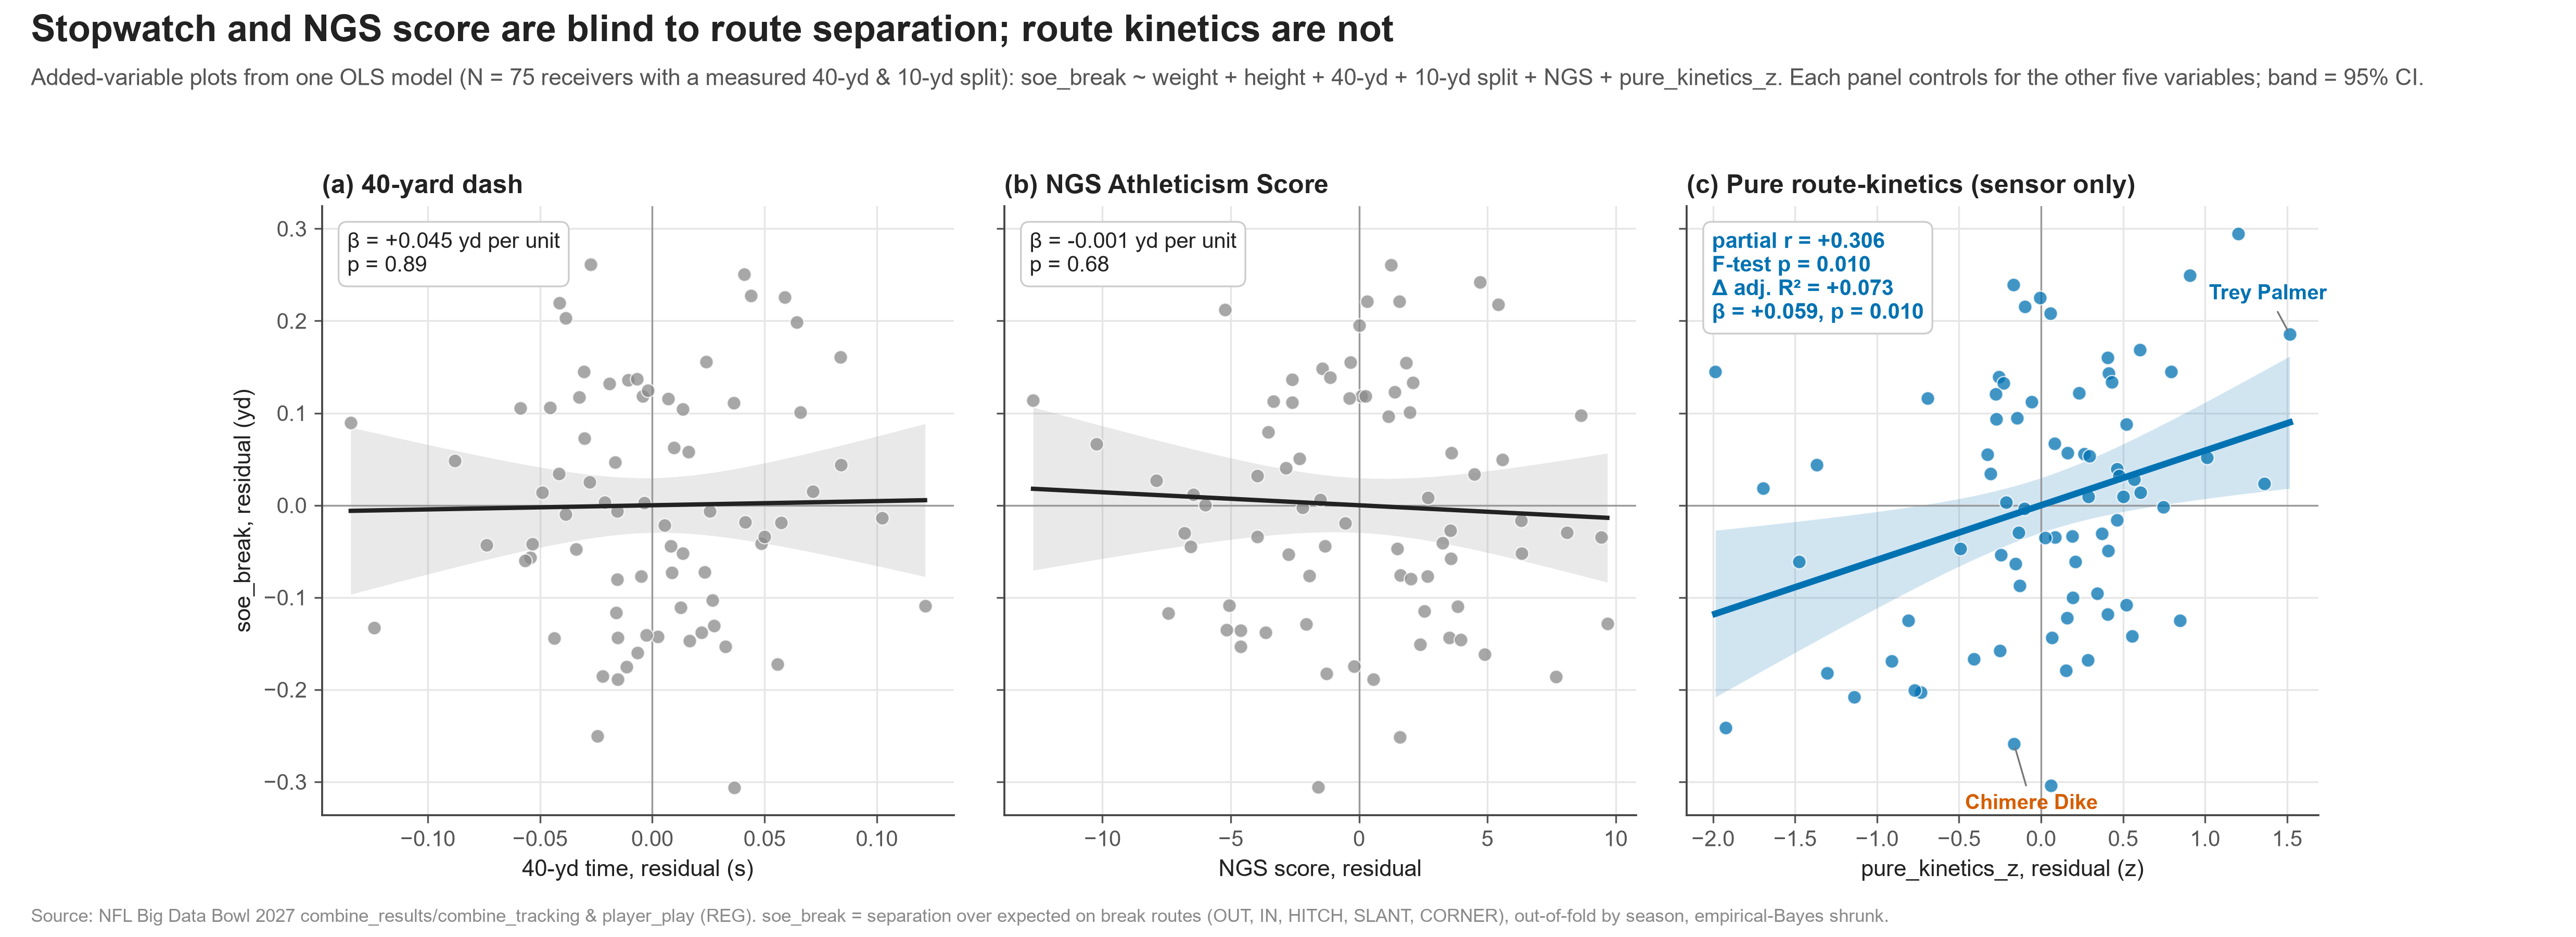

In [3]:
from pathlib import Path
from IPython.display import Image, display

fig_root = Path(globals().get('FIG_DIR', Path('../figures')))
fig_path = fig_root / 'fig2_scouting_blindspot.png'
assert fig_path.exists(), f'Missing figure: {fig_path}'
display(Image(filename=str(fig_path)))


### Combine-to-NFL Kinetic Translation (927,243 Active Game Frames)
Tracking across 35,427 regular-season route plays (927,243 snap-to-release frames) verifies direct physical transfer between February Combine drills and Sunday execution (N = 69, ≥ 50 snaps):
- **Sunday Game Speed**: `vertical_route_max_s_z` correlates strongly with NFL 95th-percentile in-game route speed (`nfl_route_p95_s`, **Spearman $\rho = +0.455, p < 0.001$**), confirming full-stride Combine speed captures Sunday velocity.
- **Separation & Expected YAC**: `pure_kinetics_z` predicts both `soe_break` (**$\rho = +0.293, p = 0.015$**) and NFL Expected YAC (`mean_expected_yac`, **$\rho = +0.301, p = 0.012$**; `vertical_route_max_s_z` **$\rho = +0.320, p = 0.007$**), as in-stride separation creates catch-and-run space. By contrast, `ngs_athleticism_score` yields near-zero noise across every outcome (-0.094 separation, +0.013 Expected YAC, +0.127 route speed; all $p \ge 0.30$).
- **Deceleration Transfer**: Combine `apex_speed_retention` correlates with sharper NFL break deceleration (more negative `nfl_break_decel_p05`: **Spearman $\rho = -0.263$, $p = 0.029$**; Pearson $r = -0.337$), confirming stopping mechanics transfer onto Sundays.

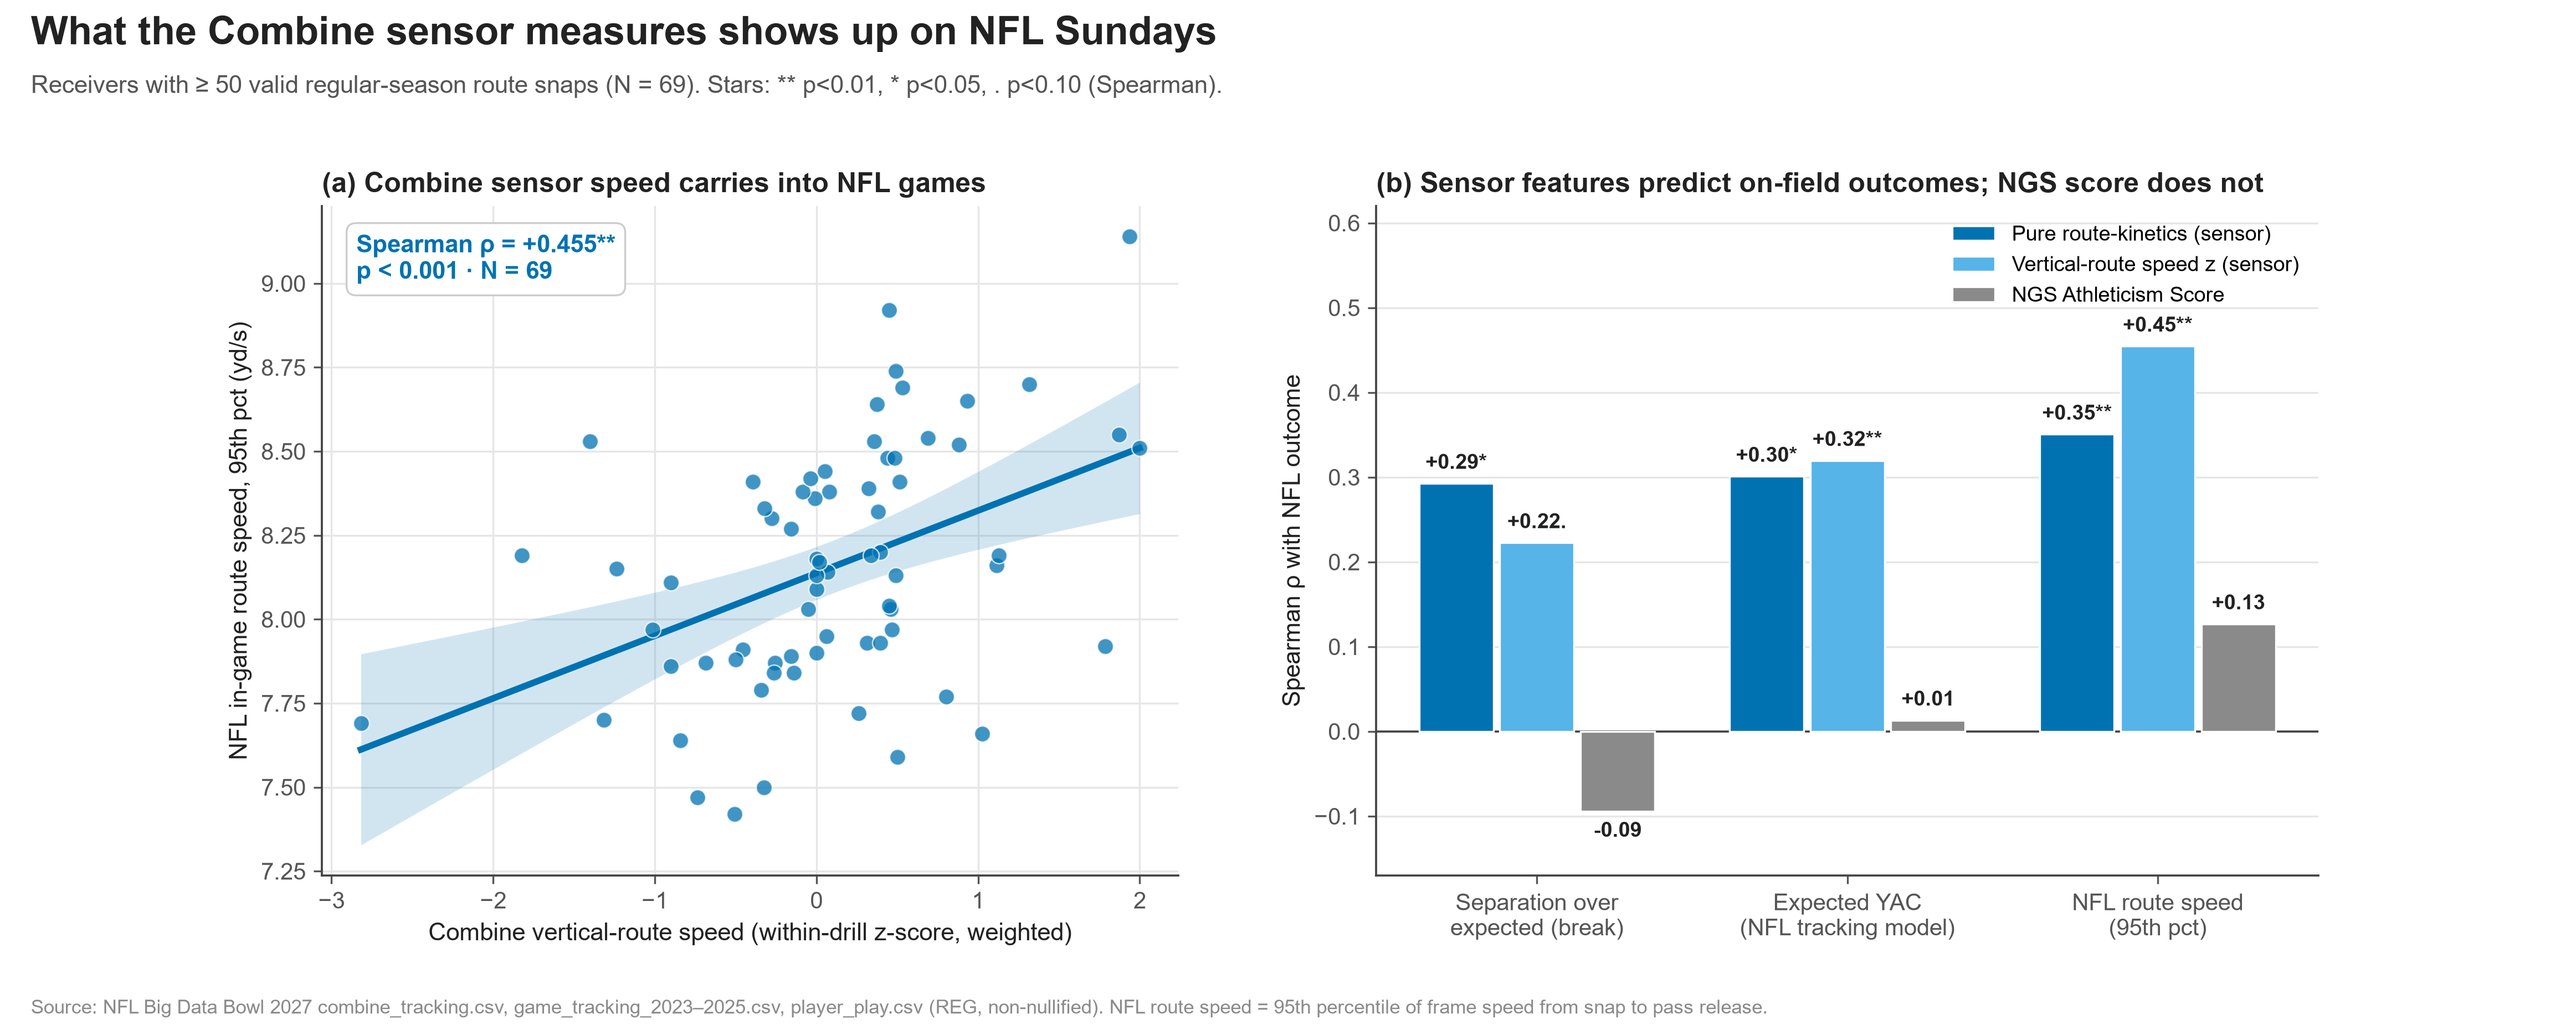

In [4]:
from pathlib import Path
from IPython.display import Image, display

fig_root = Path(globals().get('FIG_DIR', Path('../figures')))
fig_path = fig_root / 'fig3_combine_to_nfl_bridge.png'
assert fig_path.exists(), f'Missing figure: {fig_path}'
display(Image(filename=str(fig_path)))


### Blind Out-of-Sample Generalization (Clean LODCO CV, 2023–2025)
To enforce zero parameter leakage and zero global weight-mixing, we conducted Leave-One-Draft-Class-Out CV (training on two classes, predicting the held-out draft class completely blind), fitting imputation, scaling, univariate screening, and weight-residualization strictly inside each training fold. While pure sensors alone lack body-mass context (Model B), combining them with baseline size/track priors (Model C) boosts OOF $R^2$, cuts RMSE, and improves draft-class rank stability (Figure 4, Table 1).

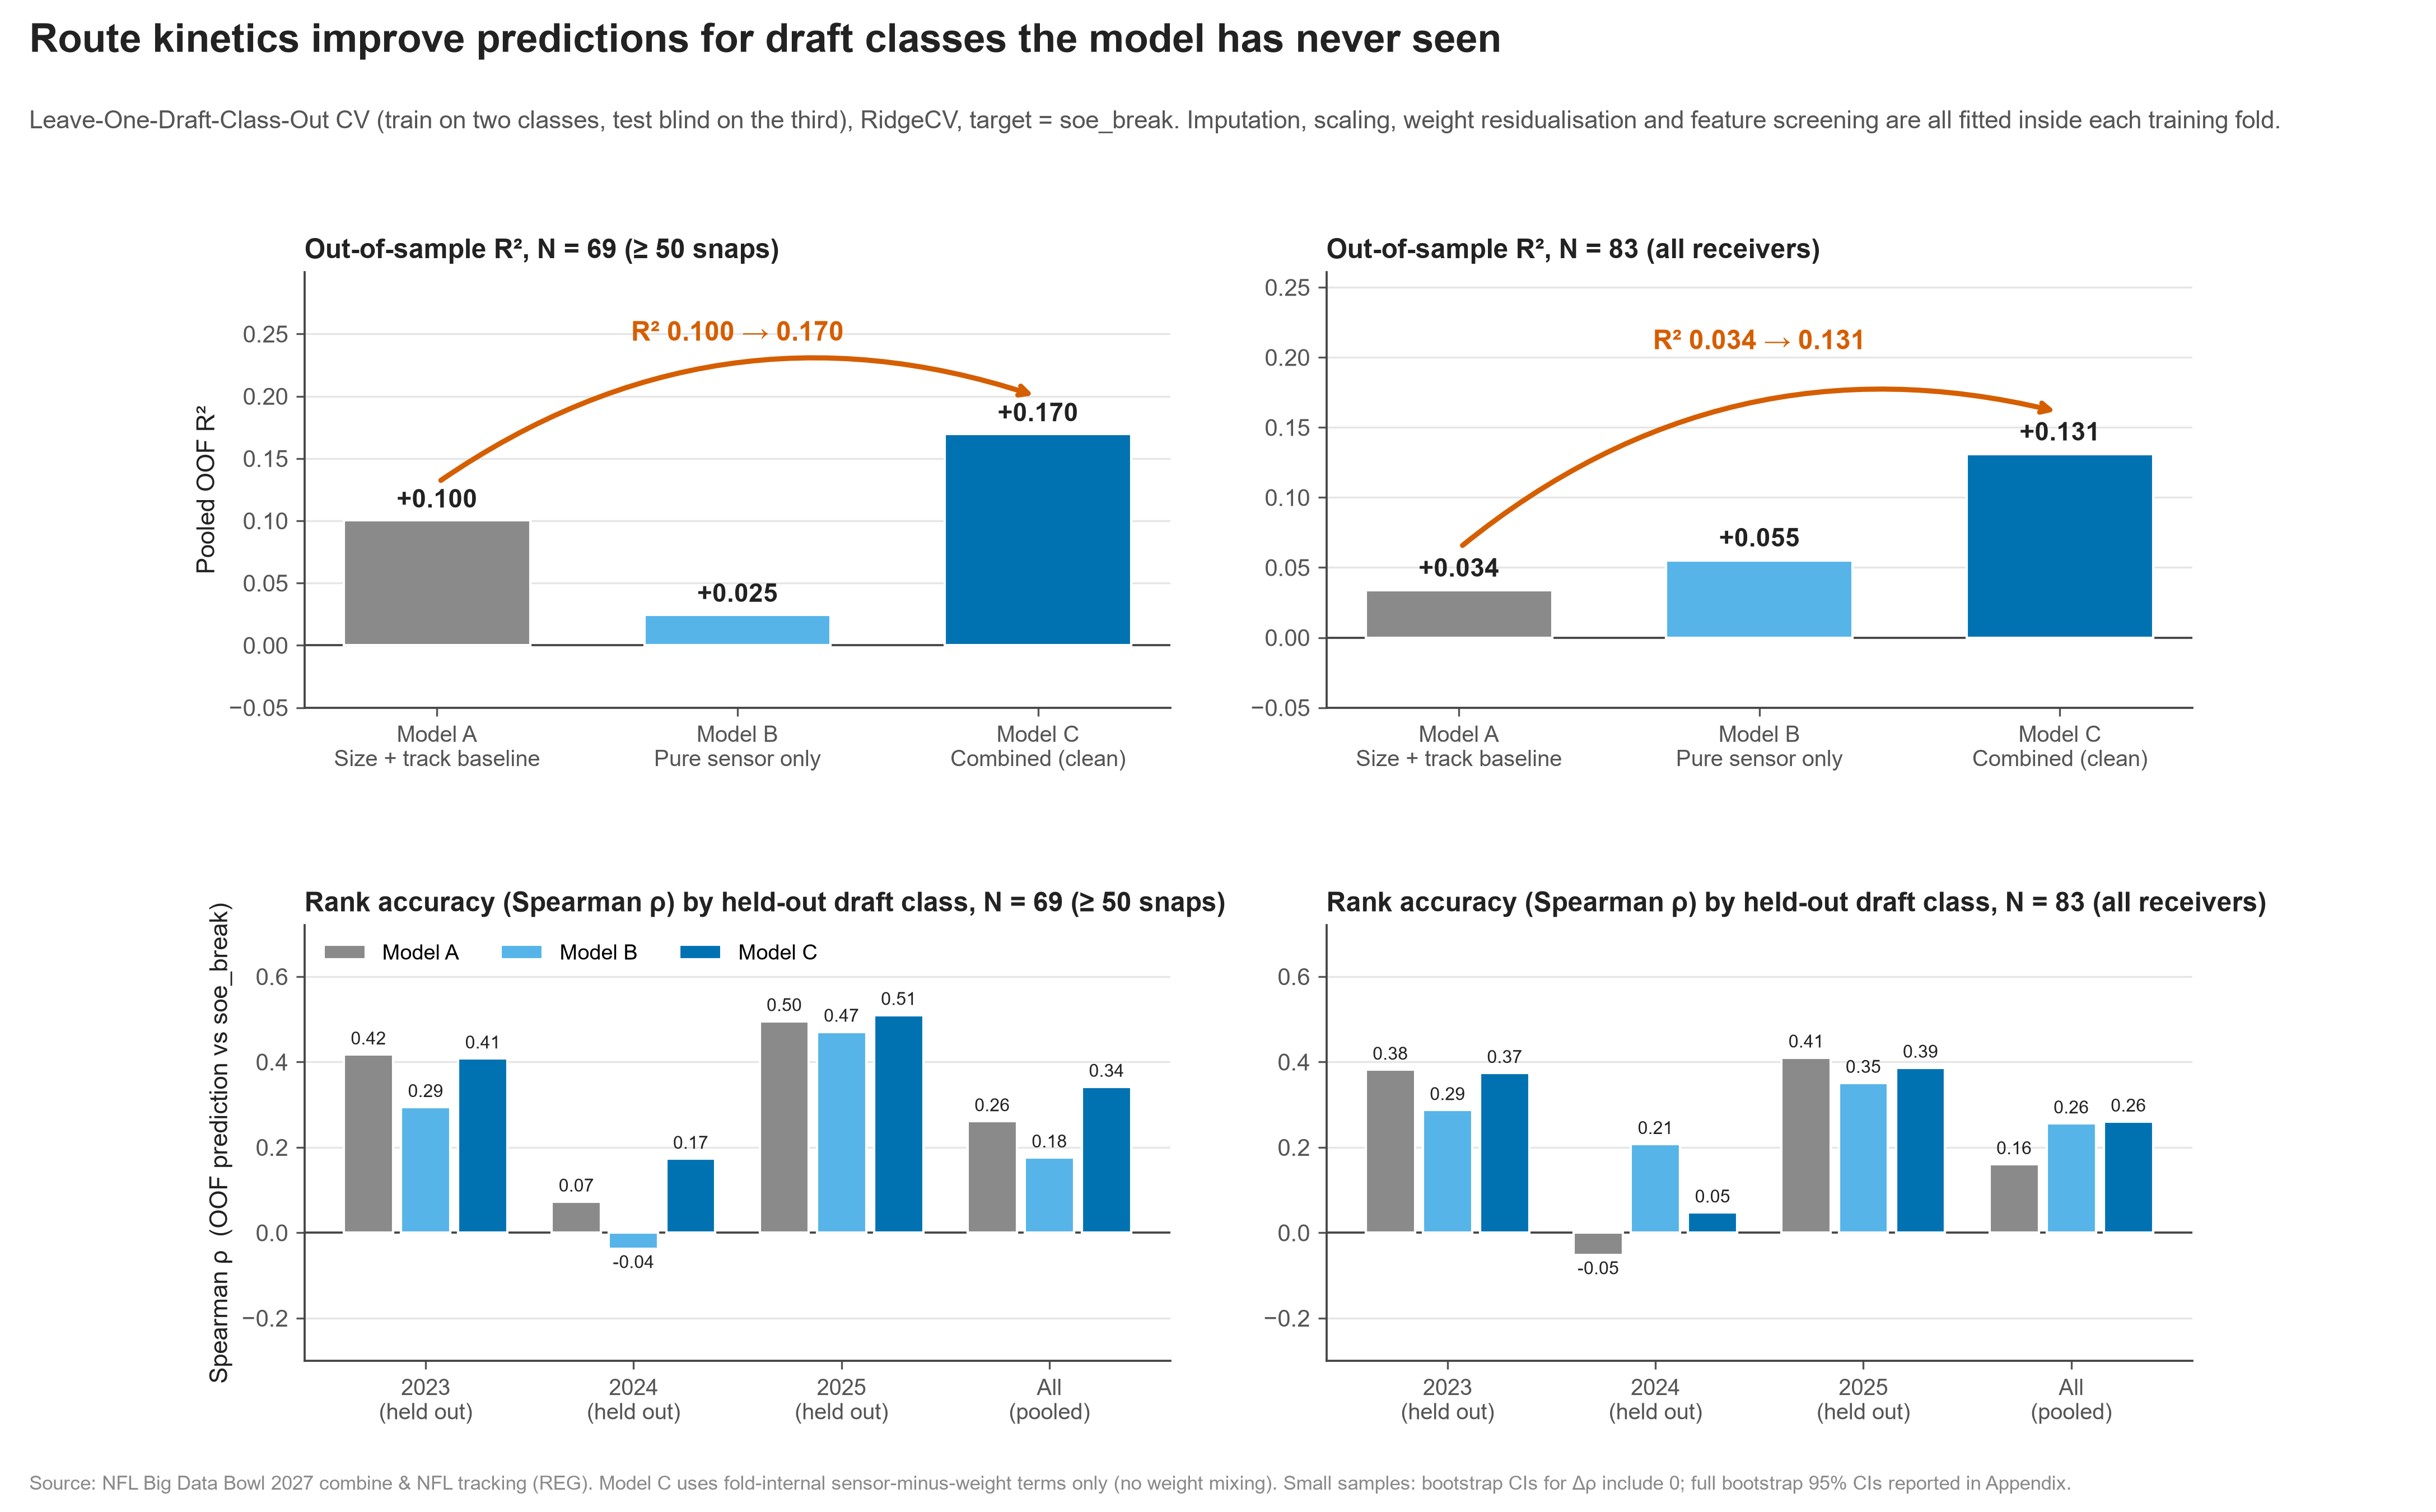

In [5]:
from pathlib import Path
from IPython.display import Image, display

fig_root = Path(globals().get('FIG_DIR', Path('../figures')))
fig_path = fig_root / 'fig4_lodco_cv_performance.png'
assert fig_path.exists(), f'Missing figure: {fig_path}'
display(Image(filename=str(fig_path)))


**Table 1: Nested OLS F-Tests and Clean Leave-One-Draft-Class-Out (LODCO) Cross-Validation (`soe_break`)**

|Validation Cohort|Model / Feature Added|OOF $R^2$|OOF RMSE|Rank $\rho$ / Partial $r$|Significance / 95% Boot CI|
|:---|:---|---:|---:|---:|:---|
|Nested OLS (N=75, complete 40)|Baseline → +`pure_kinetics_z`|Adj 0.097→0.169|—|Partial r=+0.306|F=7.023, p=0.010 (LR p=0.007)|
|Nested OLS (N=64, ≥50 snaps)|Baseline → +`pure_kinetics_z`|Adj 0.170→0.226|—|Partial r=+0.288|F=5.171, p=0.027 (LR p=0.018)|
|LODCO RidgeCV (N=69, ≥50 snaps)|Model A (Size + Track)|+0.1003|0.1472|+0.261 (p=0.030)|Baseline reference|
|LODCO RidgeCV (N=69, ≥50 snaps)|Model B (Pure Sensor Only)|+0.0246|0.1532|+0.176 (p=0.148)|$\Delta\rho=-0.085$ [-0.366,+0.217]|
|LODCO RidgeCV (N=69, ≥50 snaps)|Model C (Combined Clean)|**+0.1696**|**0.1414**|**+0.342** (p=0.004)|$\Delta\rho=+0.081$ [-0.075,+0.241]|
|LODCO BayesianRidge (N=69)|Model A → Model C|+0.110→+0.174|0.146→0.141|+0.274→+0.343|$\Delta\rho=+0.069$ [-0.082,+0.226]|
|LODCO RidgeCV (N=83, All WRs)|Model A → Model C|+0.034→+0.131|0.143→0.136|+0.160→+0.260|$\Delta\rho=+0.100$ [-0.058,+0.255]|
|LODCO ElasticNetCV (N=83)|Model A → Model C|+0.020→+0.128|0.144→0.136|+0.151→+0.296|$\Delta\rho=+0.145$ [-0.019,+0.298]|

## NFL Front-Office Application — What Changes on Monday?

Figure 5 translates this framework into a Draft-Room Quadrant plotting 40-yard dash speed against `size_adjusted_route_kinetics` (N = 57 complete-40, Go-tested WRs with ≥ 50 snaps; 41/57 carry positive size-adjusted kinetics, and 24/57 occupy the high-kinetics, positive-`soe_break` frontier). The board distinguishes **Complete Route Burners** (Trey Palmer, Jalin Hyatt, Tre Tucker), who convert Combine speed into NFL separation, from **Track-Only Profiles** (Chimere Dike, Jamari Thrash) whose linear speed stalls in route transitions. Moreover, sensors unmask 40-yard skippers (Jack Bech, Rd 2 #58, 214 lb, 9.87 yd/s drill peak, -0.302 yd `soe_break`) while elevating **below-median-40 / Day 3 sleepers** (Tez Johnson, Jimmy Horn) who cleared +1.0 in size-adjusted kinetics (Table 2).

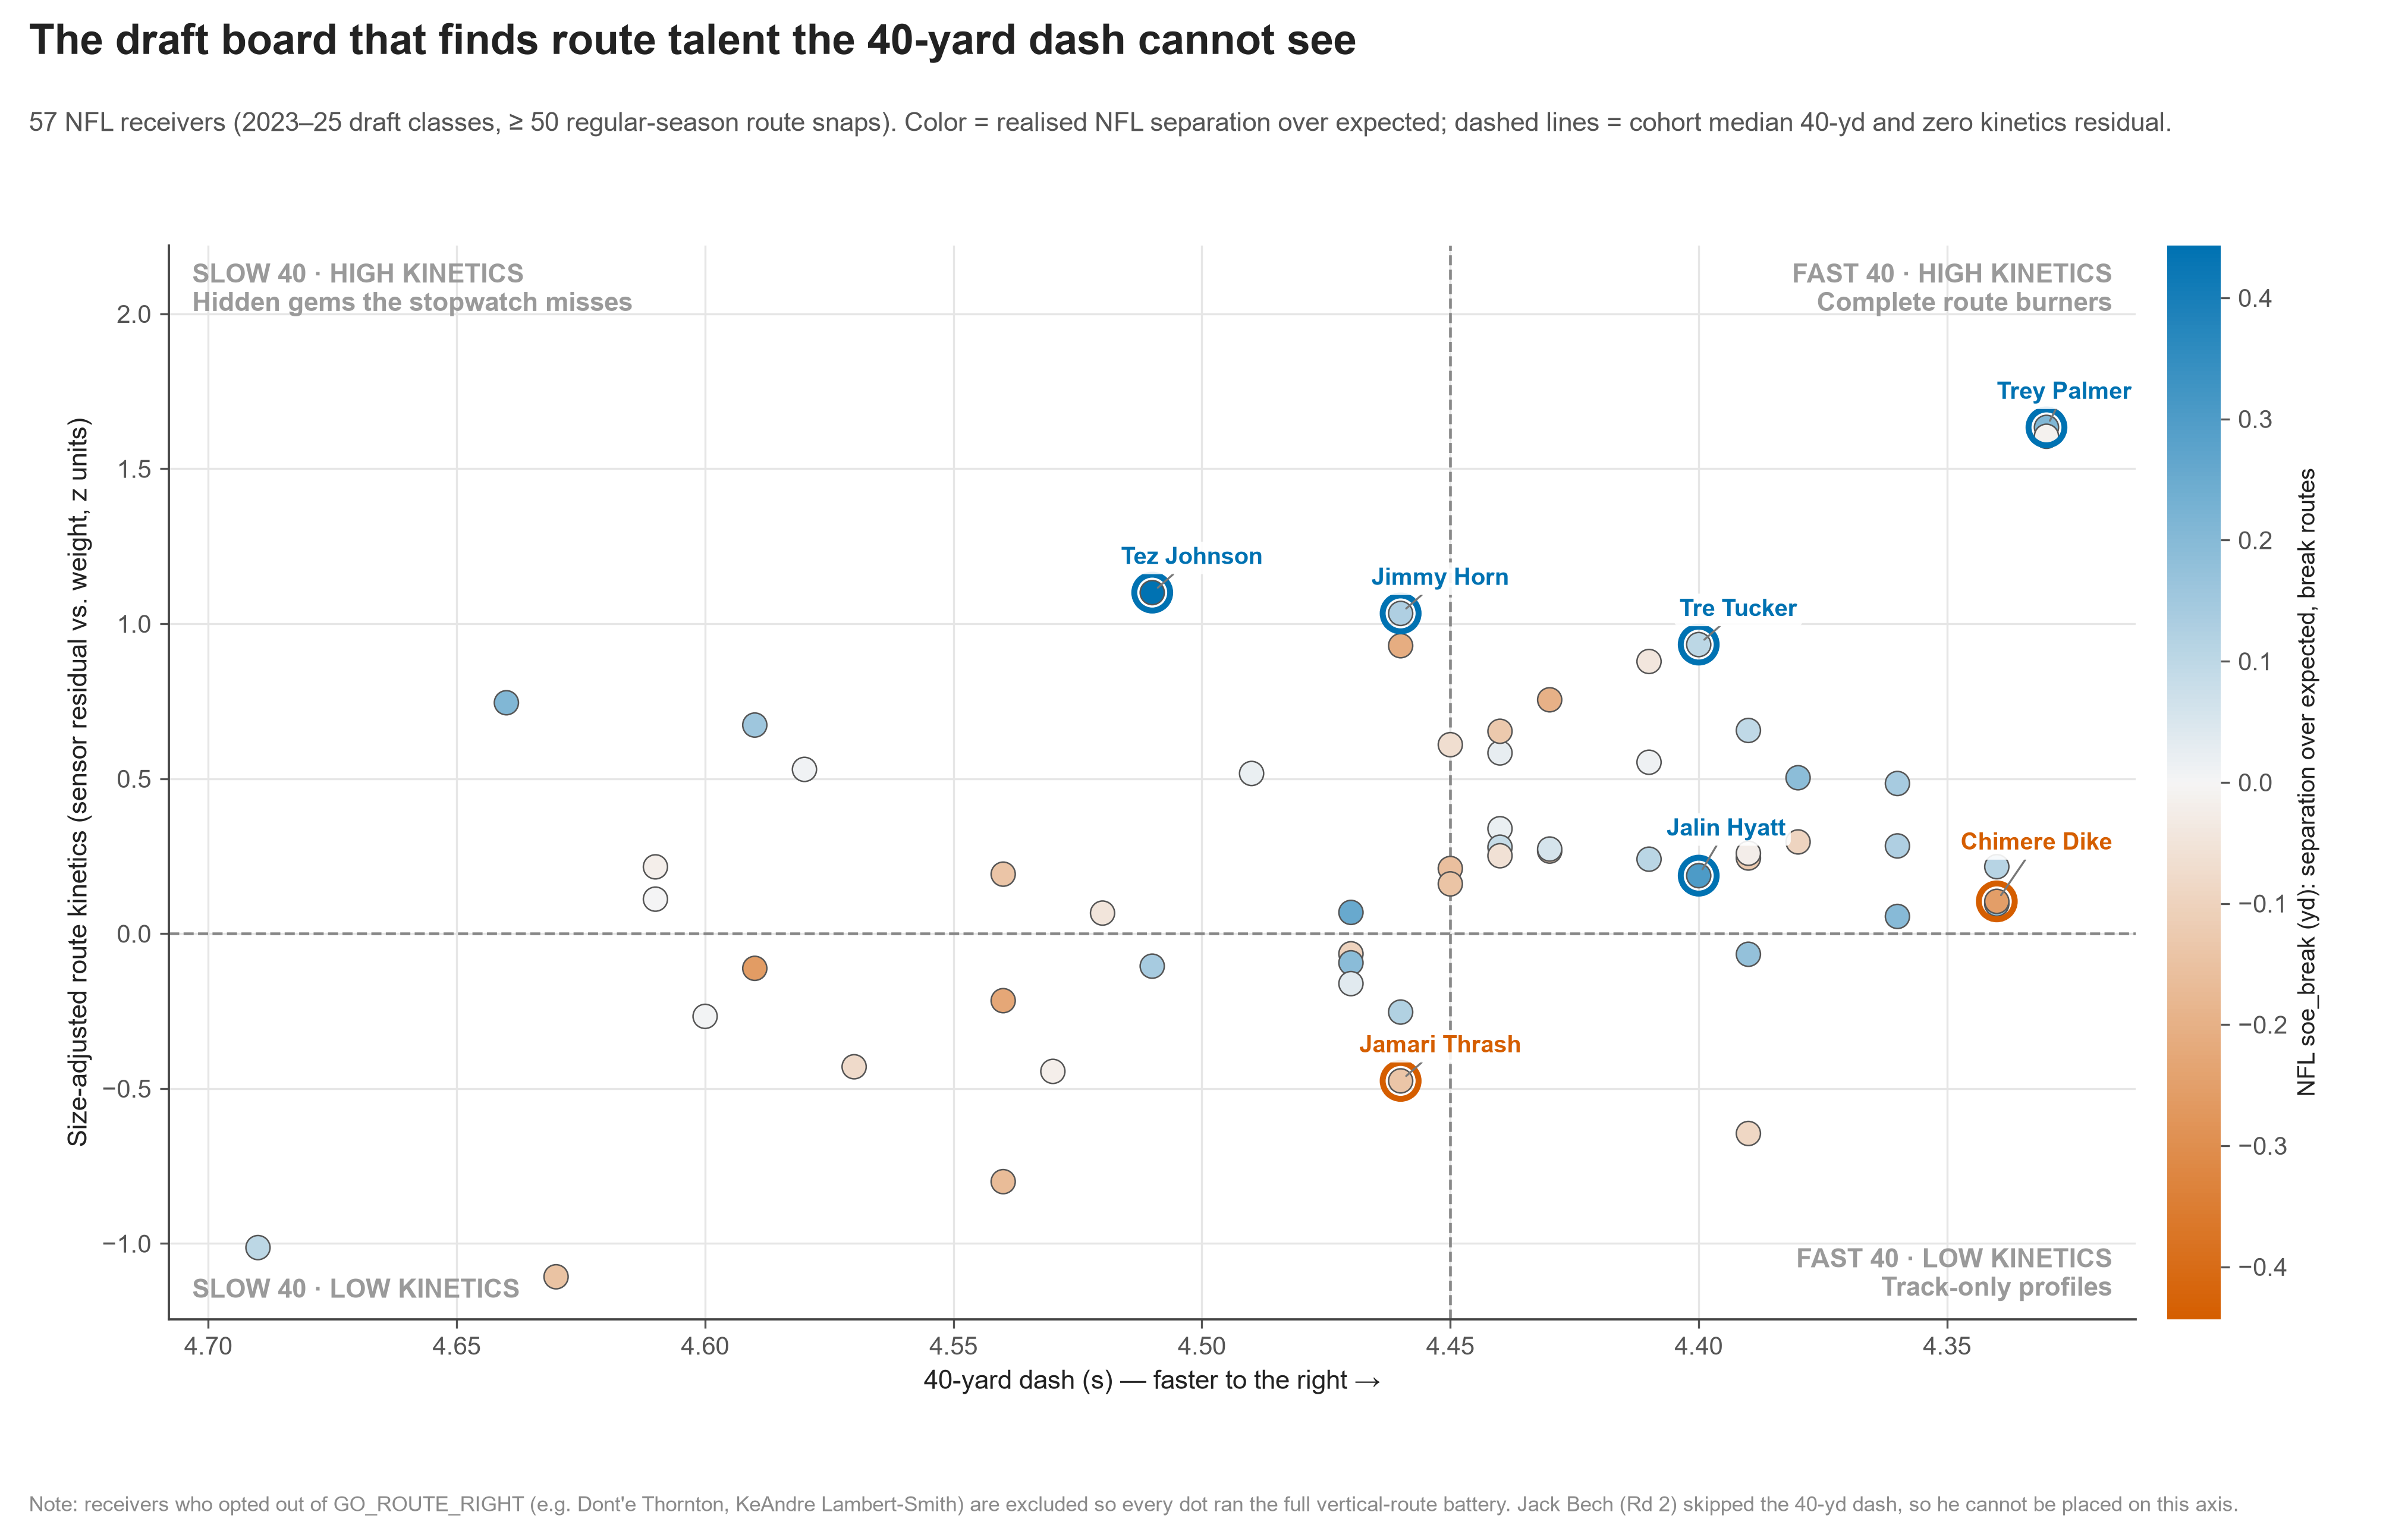

In [6]:
from pathlib import Path
from IPython.display import Image, display

fig_root = Path(globals().get('FIG_DIR', Path('../figures')))
fig_path = fig_root / 'fig5_draft_room_quadrant.png'
assert fig_path.exists(), f'Missing figure: {fig_path}'
display(Image(filename=str(fig_path)))


**Table 2: Combine-to-NFL Scouting Board — Hidden Gems vs. Overvalued Profiles**

|Receiver|Draft Pick|Weight|40-Yd|Drill `max_s`|`pure_kin_z`|`size_adj`|NFL `p95_s`|NFL `soe_break`|Archetype|
|:---|:---:|---:|---:|---:|---:|---:|---:|---:|:---|
|**Tez Johnson**|2025 Rd7 (#235)|154 lb|4.51s|10.84|+1.55|+1.10|8.51|**+0.443 yd**|Below-Med 40 Gem|
|**Jalin Hyatt**|2023 Rd3 (#73)|176 lb|4.40s|10.35|+0.41|+0.19|8.69|**+0.305 yd**|Route Burner|
|**Trey Palmer**|2023 Rd6 (#191)|192 lb|4.33s|10.98|+1.69|+1.63|8.55|**+0.211 yd**|Route Burner|
|**Jimmy Horn**|2025 Rd6 (#208)|174 lb|4.46s|10.69|+1.27|+1.03|9.14|**+0.127 yd**|Day 3 Gem|
|**Tre Tucker**|2023 Rd3 (#100)|182 lb|4.40s|10.63|+1.09|+0.93|8.65|**+0.103 yd**|Route Burner|
|**Jamari Thrash**|2024 Rd5 (#156)|188 lb|4.46s|9.87|-0.38|-0.48|7.64|**-0.139 yd**|Low Kinetics|
|**Chimere Dike**|2025 Rd4 (#103)|196 lb|4.34s|10.13|+0.12|+0.10|8.19|**-0.256 yd**|Track-Only|
|**Jack Bech**|2025 Rd2 (#58)|214 lb|—|9.87|-0.32|-0.14|7.50|**-0.302 yd**|40-Skip / Low-Sep|

### Monday Scouting Workflow for NFL Clubs
1. **Audit Opt-Outs First**: Flag prospects skipping `GO_ROUTE_RIGHT` or `POST_CORNER_ROUTE_RIGHT` (Dont'e Thornton, KeAndre Lambert-Smith) and evaluate them strictly via observed within-drill `route_speed_z` rather than penalized composites.
2. **Replace Generic Composites**: Grade separation movement using `size_adjusted_route_kinetics` within *Vertical*, *Hard-Break*, and *Speed-Cut* drill families instead of uninformative `ngs_athleticism_score` thresholds.
3. **Target Day 3 Arbitrage**: Prioritize below-median-40 / Day 3 sleepers (Tez Johnson, Jimmy Horn; `size_adjusted_route_kinetics` ≥ +0.8) while assigning fast-40 / low-kinetics track profiles (Chimere Dike) to linear vertical depth roles.

## Limitations, Future Work & Statistical Appendix

- **1. Sample Size & Bootstrap Uncertainty**: Only three Combine-to-NFL cohorts (N = 69–83) overlap; thus, while nested OLS tests (p = 0.010 at N = 75) and combined LODCO gains consistently favor sensor fusion across RidgeCV ($R^2$ 0.100→0.170 on N = 69; 0.034→0.131 on N = 83), BayesianRidge ($\Delta\rho = +0.069$ [-0.082, +0.226]; $\Delta\text{RMSE} = -0.0053$ [-0.0139, +0.0029]), and ElasticNetCV (N = 83: $\Delta\rho = +0.145$ [-0.019, +0.298]; $\Delta\text{RMSE} = -0.0082$ [-0.0164, +0.0004]), **2,000-replicate paired bootstrap 95% CIs on RidgeCV $\Delta\rho$ ([-0.075, +0.241] on N = 69; [-0.058, +0.255] on N = 83) and $\Delta\text{RMSE}$ ([-0.0149, +0.0031] on N = 69; [-0.0151, -0.0000] on N = 83) cross or touch zero**, reflecting small cohort size.
- **2. Missing Orientation & Live Defender Leverage**: Combine tracking captures center-of-mass motion without upper-body orientation (`o`) or live defensive-back leverage, leaving head fakes and press release battles unmeasured.
- **3. Voluntary Drill Opt-Outs**: Selective Combine drill skipping biases unadjusted multi-drill averages unless flagged via `has_go_route` and graded strictly on observed `route_speed_z`.

Accumulating future Combine classes and extending biomechanical tracking to defensive back coverage-transition drills will tighten statistical bounds and unlock spatial WR–DB matchup modeling before Draft Night.

In [7]:
# Reproducibility verification against generated processed artifacts (hidden input on Kaggle)
import json
from pathlib import Path
import polars as pl
from scipy import stats

proc = Path(globals().get("PROC_DIR", Path("../data/processed")))
targets = pl.read_parquet(proc / "wr_targets.parquet")
adv = pl.read_parquet(proc / "wr_advanced_kinetics.parquet")
gk = pl.read_parquet(proc / "wr_game_kinetics.parquet")
oof = json.loads((proc / "wr_oof_metrics.json").read_text(encoding="utf-8"))
df = (
    targets.join(adv, on="nfl_id", how="inner", suffix="_adv")
    .join(gk, on="nfl_id", how="inner", suffix="_gk")
    .filter(pl.col("soe_break").is_not_null())
)
df50 = df.filter(pl.col("n_all") >= 50)
rho_p95, p_p95 = stats.spearmanr(df50["vertical_route_max_s_z"], df50["nfl_route_p95_s"])
rho_soe, p_soe = stats.spearmanr(df50["pure_kinetics_z"], df50["soe_break"])
summary = (
    f"Verified cohorts: N_all={df.height}, N_50={df50.height}, OOF_R2={oof['overall']['r2']:.4f}\n"
    f"Verified N=50 Spearman: vert_max_s_z->p95={rho_p95:+.3f} (p={p_p95:.2e}), "
    f"pure_kinetics_z->soe_break={rho_soe:+.3f} (p={p_soe:.4f})"
)
print(summary)


Verified cohorts: N_all=83, N_50=69, OOF_R2=0.3100
Verified N=50 Spearman: vert_max_s_z->p95=+0.455 (p=8.73e-05), pure_kinetics_z->soe_break=+0.293 (p=0.0147)
